## Trabajo práctico — Redes neuronales con NumPy y PyTorch

### Preparación
[Presentación de clase](https://docs.google.com/presentation/d/1mdyWXUdixJ9UHNxtIBKhRFODpSTmfAogFm1QsRVEcdw/edit?usp=sharing)

La primera vez puede ser necesario instalar `torch`, `torchvision`. En Colab suelen estar disponibles. Ejecutá esta celda para verificar el entorno.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
import torch
from torch import nn

SEMILLA = 42
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
print('PyTorch:', torch.__version__)
print('Dispositivo: CPU')

### 1. Perceptrón simple clásico: cálculo e implementación

### Actividad 1 — Actualización manual de los pesos

Un perceptrón tiene $x_0=1$,

dos entradas $\mathbf{x}=(1{,}5;-0{,}8)$,

pesos $\mathbf{w} = (w_0, w_1, w_2) =(0{,}2;0{,}4;-0{,}3)$,

etiqueta real $y=-1$ y tasa de aprendizaje $\eta=0{,}1$.

Calculá **a mano**:

los tres pesos nuevos actualizados. Explicá por qué se actualizan o no los pesos.

### Actividad 2 — Regla del perceptrón con NumPy

Se trabajará inicialmente con dos especies de Iris (**setosa** y **versicolor**) y dos características: largo de sépalo y largo de pétalo. Las clases se codifican como **−1** y **+1**, respectivamente.

**Consignas:**

- Identificá en la clase `Perceptron` los métodos que realizan la suma ponderada, la predicción y el ajuste de los pesos.
- Completá las líneas señaladas como `TODO` y entrená el modelo.
- Representá e interpretá **tres gráficos**:

    (1) cantidad de patrones mal clasificados por época,

    (2) error individual `e = y - y_pred` registrado para cada patrón presentado durante el entrenamiento y

    (3) datos de Iris junto con la frontera de decisión obtenida.

- Probá distintos valores de `eta` y `epocas`, y analizá cómo cambian los resultados.

**Importante:**

Estos tres gráficos deberán realizarse **en los dos experimentos** de la actividad: *setosa frente a versicolor* y *versicolor frente a virginica*.

**Recordatorio:**

El error de un patrón es $e=y-\hat y$. Con las etiquetas −1/+1 puede tomar los valores −2, 0 y +2. Ese error individual no es lo mismo que la cantidad de patrones mal clasificados por época. Esta distinción es necesaria para interpretar los gráficos.

In [ ]:
iris = load_iris()

# Primera y tercera características: largo de sépalo y largo de pétalo.
X_np = iris.data[:100, [0, 2]].astype(float)
y = np.where(iris.target[:100] == 0, -1, 1)  # -1: setosa; +1: versicolor
y_pm = y  # Se mantiene este nombre para las celdas posteriores.

plt.figure(figsize=(7, 5))
plt.scatter(X_np[:50, 0], X_np[:50, 1], color="red", marker=".", label="setosa")
plt.scatter(X_np[50:, 0], X_np[50:, 1], color="blue", marker="*", label="versicolor")
plt.xlabel("x1 = largo de sépalo [cm]")
plt.ylabel("x2 = largo de pétalo [cm]")
plt.legend()
plt.show()

In [ ]:
from numpy.random import RandomState

class Perceptron(object):
    """Perceptrón simple con la estructura de la notebook original.

    eta: tasa de aprendizaje.
    epocas: cantidad de épocas de entrenamiento.
    random_state: semilla para inicializar los pesos.
    """
    def __init__(self, eta=0.001, epocas=1, random_state=None):
        self.eta = eta
        self.epocas = epocas
        self.random_state = random_state

    def fit(self, X, y):
        """Entrena el perceptrón con la regla de corrección del error."""
        generador = RandomState(self.random_state)
        self.w2_ = generador.normal(loc=0.0, scale=0.01, size=1 + X.shape[1])
        self.mal_clasificados_ = []
        self.errores_ = []

        X = np.insert(X, 0, 1, axis=1)  # Incorporar x0 = 1 (sesgo).

        for _ in range(self.epocas):
            mal_clasificados = 0
            for xi, target in zip(X, y):
                y_pred = self.predict(xi)

                # TODO: identificar el cálculo del error y la actualización.
                # ----------------------------------------------------------------



            # ----------------------------------------------------------------
        return self

    def calcular_entrada(self, x):
        """Calcula la suma ponderada, incluido el sesgo."""
        # TODO: relacionar esta operación con la expresión matemática.
        # ----------------------------------------------------------------

        # ----------------------------------------------------------------

    def predict(self, X):
        """Devuelve la clase -1 o +1 aplicando la función umbral."""
        # TODO: identificar el umbral y sus dos posibles salidas.
        # ----------------------------------------------------------------
        # usar npware o algo asi dijo
        # ----------------------------------------------------------------

In [ ]:
# --------------Entrenar el modelo   --------------------------


# ----------------------------------------------------------------

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(perceptron.mal_clasificados_) + 1),
         perceptron.mal_clasificados_, marker="o")
plt.xlabel("Época")
plt.ylabel("Cantidad de patrones mal clasificados")
plt.title("Evolución del entrenamiento")
plt.show()

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(perceptron.errores_) + 1),
         perceptron.errores_)
plt.xlabel("Época")
plt.ylabel("Error")
plt.title("Evolución del entrenamiento")
plt.show()

### Frontera de decisión del perceptrón simple

Recordemos la ecuación de la salida del perceptrón:

$$
\hat y=\operatorname{sign}\left(w_0+\sum_{i=1}^{N}x_iw_i\right).
$$

Para este problema, con dos características ($x_1$: largo de sépalo; $x_2$: largo de pétalo), resulta:

$$
\hat y=\operatorname{sign}(x_1w_1+x_2w_2+w_0).
$$

La **frontera de decisión** corresponde a los puntos donde la entrada neta es cero:

$$
x_1w_1+x_2w_2+w_0=0.
$$

Despejando $x_2$ en función de $x_1$:

$$
x_2+x_1\frac{w_1}{w_2}+\frac{w_0}{w_2}=0,
$$

$$
\boxed{x_2=-\frac{w_1}{w_2}x_1-\frac{w_0}{w_2}}.
$$

Comparando con la ecuación de una recta $x_2=mx_1+b$, obtenemos:

$$
\boxed{m=-\frac{w_1}{w_2}},\qquad
\boxed{b=-\frac{w_0}{w_2}}.
$$

Por lo tanto, a partir de los pesos aprendidos podemos calcular la **pendiente** $m$ y la **ordenada al origen** $b$, y representar la recta junto con las dos clases.

**Consigna:** utilizá estas expresiones para construir e interpretar el gráfico de la frontera de decisión del perceptrón entrenado.


In [ ]:
# Representación de la recta de separación con los datos.
# ----------------------------------------------------------------


# ----------------------------------------------------------------

**Para analizar (en ambos experimentos):** observá la cantidad de patrones mal clasificados por época y la secuencia de errores individuales. ¿Qué diferencias encontrás entre ambos gráficos? ¿Cómo se relacionan con la frontera de decisión? ¿Qué ocurre al modificar `eta` o la cantidad de épocas?

**Segundo experimento — versicolor y virginica.**

Repetí el entrenamiento utilizando estas dos especies y las mismas características (largo de sépalo y largo de pétalo). Conservá la codificación −1/+1 y realizá nuevamente los **tres gráficos**: cantidad de patrones mal clasificados por época, errores individuales de los patrones presentados y frontera de decisión junto con los datos. Compará los resultados con los obtenidos para *setosa* y *versicolor*.

In [ ]:
# Repetir el experimento con Iris versicolor (-1) e Iris virginica (+1).
# Utilizamos las mismas características: largo de sépalo y largo de pétalo.






En la siguiente sección volveremos a usar los mismos datos, pero **ya no la regla del perceptrón clásico**: entrenaremos una neurona binaria con una función de pérdida diferenciable y descenso por gradiente en PyTorch.

### 2. Introducción a PyTorch: entrenamiento de una neurona

En la actividad anterior, el perceptrón clásico ajustó sus pesos mediante la regla de corrección del error.

En esta sección se utilizará **PyTorch** para entrenar una neurona con una función de pérdida diferenciable y descenso por gradiente.

**Preparación de las etiquetas.**

Los datos de Iris continúan codificados como −1 (setosa) y +1 (versicolor), pero la función de pérdida requiere valores 0 y 1. Se realizará la conversión:

$$
y_{\mathrm{pérdida}}=\frac{y+1}{2}.
$$

**Actividad de exploración.**

Ejecutá la celda siguiente e identificá la forma (`shape`) y el tipo (`dtype`) de los tensores de entrada y de las etiquetas.

In [ ]:
X_tensor = torch.tensor(X_np, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.float32).unsqueeze(1)
y_perdida = (y_tensor + 1) / 2  # Solo para BCEWithLogitsLoss: -1 -> 0, +1 -> 1.
print('Entradas:', X_tensor.shape, X_tensor.dtype)
print('Etiquetas:', y_tensor.shape, y_tensor.dtype)
print('Ejemplo:', X_tensor[0], y_tensor[0], '-> objetivo de pérdida:', y_perdida[0])

In [ ]:
class NeuronaBinaria(nn.Module):
    def __init__(self):
        super().__init__()
        self.lineal = nn.Linear(2, 1)

    def forward(self, x):
        return self.lineal(x)

In [ ]:
modelo = NeuronaBinaria()
print(modelo.lineal.weight)
print(modelo.lineal.bias)

In [ ]:
criterio = nn.BCEWithLogitsLoss() # En Pytorch a las funciones de pérdida se las llama "criterio" (loss function).
optimizador = torch.optim.SGD(modelo.parameters(), lr=0.1)
print(modelo)

### Actividad 3 — Entrenamiento de una neurona con PyTorch

**Ciclo de entrenamiento.** Observá y analizá cada una de las partes de la función `entrenar_modelo_binario()`:

- `optimizador.zero_grad()`

    La instrucción `zero_grad()` es necesaria porque PyTorch acumula los gradientes de manera predeterminada. Al limpiarlos, nos aseguramos de que cada actualización utilice los gradientes correspondientes al cálculo actual.

- `modelo(X)`

    Esta instrucción realiza la propagación hacia adelante (forward propagation). Cuando se llama a `modelo(X)` PyTorch ejecuta internamente el método `forward()` que definimos en nuestra clase.

- `criterio(salidas, y)`

    Calcula la pérdida entre las salidas de la red y las etiquetas. Como estamos usando `BCEWithLogitsLoss()` Primero transforma cada logit en una probabilidad estimada mediante la función sigmoidea y después evalúa esas probabilidades utilizando entropía cruzada binaria para calcular el error. Como estamos procesando todos los datos juntos, BCEWithLogitsLoss devuelve, por defecto, la pérdida promedio de los 100 patrones.

- `perdida.backward()`

    `backward()` calcula los gradientes de la pérdida respecto de los parámetros entrenables mediante diferenciación automática (autograd).

- `optimizador.step()`

    `step()` utiliza esos gradientes para actualizar los parámetros siguiendo el algoritmo de optimización elegido.

Ejecutá el entrenamiento y representá la evolución de la pérdida. ¿Qué tendencia observás? ¿Es necesariamente decreciente en todas las épocas?

In [ ]:
def entrenar_modelo_binario(modelo, X, y, criterio, optimizador, epocas=100):
    historial = [] #guarda perdida de cada epoca
    for epoca in range(epocas):
        optimizador.zero_grad()
        #calcula gradientes con todos los datos
        salidas = modelo(X) # es lo mismo que llamar a modelo.forward(X) (nuesto modelo es la red neuronal)
        perdida = criterio(salidas, y) # calcula la pérdida entre las salidas y las etiquetas
        perdida.backward()
        optimizador.step()
        # perdida es un tensor de PyTorch, aunque contenga un único número.
        # El método .item() extrae ese valor como número de Python.
        # Lo convertimos a float y lo agregamos a la lista.
        historial.append(float(perdida.item()))
    return historial

In [ ]:
criterio = nn.BCEWithLogitsLoss()
optimizador = torch.optim.SGD(modelo.parameters(), lr=0.1)
historial = entrenar_modelo_binario(modelo, X_tensor, y_perdida, criterio, optimizador, epocas=120)

plt.plot(historial)
plt.xlabel('Época')
plt.ylabel('Pérdida de entrenamiento')
plt.title('Entrenamiento mediante gradientes')
plt.show()

**Frontera de decisión.**

Reutilizá el despeje de la recta de separación presentado en la **Actividad 2**.

Con los pesos y el sesgo que ya proporciona la celda siguiente, completá únicamente el código delimitado por las líneas punteadas para graficar esa recta junto con los datos de *Iris setosa* y *Iris versicolor*.

In [ ]:
# Obtener los pesos y el sesgo de la neurona entrenada
pesos = modelo.lineal.weight.detach().numpy()[0]
w0 = modelo.lineal.bias.detach().item()

#----------------------------------------------------------------


# ----------------------------------------------------------------

**Experimentación con la tasa de aprendizaje.**

Ejecutá el bloque siguiente para entrenar dos neuronas nuevas, una con `lr=0.01` y otra con `lr=0.1`. Compará sus curvas de pérdida. ¿Cuál disminuye más rápidamente en las primeras épocas? ¿Se puede concluir que una tasa de aprendizaje mayor siempre es mejor?

In [ ]:
# Comparación de dos tasas de aprendizaje usando la misma inicialización.
plt.figure(figsize=(7, 4))

for tasa_aprendizaje in [0.01, 0.1]:
    torch.manual_seed(42)
    modelo_comparacion = NeuronaBinaria()
    criterio_comparacion = nn.BCEWithLogitsLoss()
    optimizador_comparacion = torch.optim.SGD(
        modelo_comparacion.parameters(), lr=tasa_aprendizaje
    )

    historial_comparacion = entrenar_modelo_binario(
        modelo_comparacion, X_tensor, y_perdida,
        criterio_comparacion, optimizador_comparacion, epocas=120
    )
    plt.plot(historial_comparacion, label=f"lr = {tasa_aprendizaje}")

plt.xlabel("Época")
plt.ylabel("Pérdida de entrenamiento")
plt.title("Comparación de tasas de aprendizaje")
plt.legend()
plt.show()

### 3. Perceptrón multicapa y problema XOR

En las actividades anteriores clasificamos datos mediante modelos con una única neurona y una frontera de decisión lineal.

Ahora utilizaremos **XOR** (*OR exclusivo*), cuya salida es 1 cuando las dos entradas son diferentes y 0 cuando son iguales.

| $x_1$ | $x_2$ | XOR |
|---:|---:|---:|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

Las dos clases **no son linealmente separables**: ninguna recta puede separar correctamente los cuatro patrones.

El archivo `datos_xor_binario.mat` contiene 80 ejemplos con dos características y etiquetas 0/1 para explorar este problema.

Para resolver XOR utilizaremos un **perceptrón multicapa 2–2–1**: dos entradas, dos neuronas en la capa oculta con activación `Tanh` y una salida lineal (**logit**).

Seguiremos usando `BCEWithLogitsLoss` y la función de entrenamiento de la Actividad 3.

**Exploración:** ejecutá la celda siguiente, observá que los patrones no se pueden separar mediante una única recta.

Forma de las entradas: torch.Size([80, 2])
Forma de las etiquetas: torch.Size([80, 1])
Clases: tensor([0., 1.])


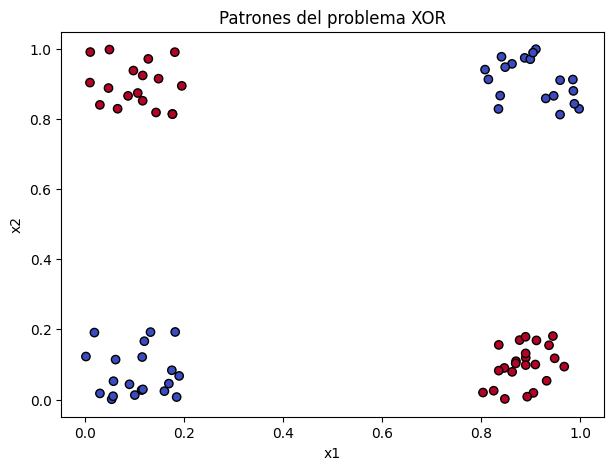

In [ ]:
from scipy.io import loadmat

# Cargar los patrones desde el archivo externo.
datos_xor = loadmat("./ActividadesPracticas/AM_RedesNeuronales/1_datos/datos_xor_binario.mat")
X_xor = torch.tensor(datos_xor["X"], dtype=torch.float32)
y_xor = torch.tensor(datos_xor["Y"].reshape(-1, 1), dtype=torch.float32)

print("Forma de las entradas:", X_xor.shape)
print("Forma de las etiquetas:", y_xor.shape)
print("Clases:", torch.unique(y_xor))

plt.figure(figsize=(7, 5))
plt.scatter(X_xor[:, 0], X_xor[:, 1],
            c=y_xor[:, 0], cmap="coolwarm", edgecolor="k")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Patrones del problema XOR")
plt.show()

### Actividad 4 — Perceptrón multicapa para XOR

**Parte A. Arquitectura.**

Identificá las dos capas `nn.Linear`, la función `Tanh` y la salida del modelo.  

In [ ]:
class RedXOR(nn.Module):
    def __init__(self, neuronas_ocultas=2):
        super().__init__()

        # Definir las capas de la red
        self.capa_oculta = nn.Linear(2, neuronas_ocultas)
        self.activacion = nn.Tanh()
        self.capa_salida = nn.Linear(neuronas_ocultas, 1)

    def forward(self, x):

        # Primera capa: suma ponderada y sesgo
        z1 = self.capa_oculta(x)

        # Función de activación de la capa oculta
        h = self.activacion(z1)

        # Segunda capa: cálculo del logit de salida
        z2 = self.capa_salida(h)

        return z2

**Parte B. Entrenamiento con SGD.**

Entrená el modelo reutilizando `entrenar_modelo_binario()`, como en la Actividad 3.

Luego, **graficá la pérdida de entrenamiento en función de las épocas** utilizando el historial devuelto por esa función. Observá si la pérdida disminuye y cómo evoluciona durante el entrenamiento.

In [ ]:
torch.manual_seed(7)
# ---------------------------------------------------------------------
modelo_xor = ...


#---------------------------------------------------------------------

In [ ]:
# ----------------------------------------------------------------------

# ---------------------------------------------------------------------

**Predicciones del modelo.**

Utilizá la función `predecir()` que se proporciona a continuación y ejecutá el ejemplo para evaluar el modelo entrenado con SGD sobre los patrones XOR. La función transforma los logits en probabilidades mediante `torch.sigmoid()` y asigna las clases 0/1 con un umbral de 0,5.

Observá la exactitud obtenida. Esta corresponde a los **datos de entrenamiento** y nos permitirá comparar luego el resultado con Adam.

In [ ]:
def predecir(modelo, X):
    modelo.eval()

    with torch.no_grad():
        # Obtener los logits de la red
        logits = modelo(X)

        # Convertir los logits en probabilidades
        probabilidades = torch.sigmoid(logits)

        # Asignar la clase según el umbral de 0.5
        predicciones = torch.where(probabilidades >= 0.5, 1, 0)

    return predicciones, probabilidades

In [ ]:
predicciones, probabilidades = predecir(modelo_xor, X_xor)

exactitud = (predicciones == y_xor).float().mean().item()

print(f"Exactitud de entrenamiento: {exactitud*100}%")

**Parte C. Comparación con Adam.**

Adam es otro optimizador basado en gradientes. Para comparar su comportamiento con SGD, **creá y entrená un nuevo modelo `RedXOR`**, con la misma arquitectura y los mismos datos. Utilizá la misma semilla de inicialización y cantidad de épocas que en la Parte B, pero cambiá el optimizador por Adam:

```python
optimizador_adam = torch.optim.Adam(modelo_adam.parameters(), lr=0.01)
```

**Graficá ambas curvas de pérdida en una misma figura**, utilizando los historiales de SGD y Adam, e interpretá las diferencias observadas.

Finalmente, **volvé a utilizar la función `predecir()` proporcionada anteriormente**, esta vez con `modelo_adam`. Calculá la exactitud de entrenamiento y comparala con la obtenida mediante SGD. ¿Qué diferencias observás en la evolución de la pérdida y en las predicciones?

La tasa de aprendizaje no tiene por qué ser igual para ambos optimizadores; una comparación entre estas configuraciones no permite concluir que uno sea siempre superior al otro.

In [ ]:
# Entrenar desde la misma inicialización para comparar SGD y Adam.
torch.manual_seed(7)
# ------------------------------------------------------------------------------


# ------------------------------------------------------------------------------

In [ ]:
# ---------------------------------------------------------------

#-------------------------------------------------------------

### 4. Redes convolucionales: diseño antes de entrenar

Para convoluciones 2D estándar, la dimensión de salida de cada eje es

$$O=\left\lfloor\frac{W-F+2P}{S}\right\rfloor+1.$$

Las dimensiones **alto y ancho** se calculan por separado si difieren. En pooling se puede aplicar una fórmula análoga usando los parámetros de esa operación.

In [ ]:
# W: tamaño de la entrada (ancho y alto)
# F: tamaño del filtro (kernel)
# P: padding
# S: stride
casos = [(28, 3, 0, 1), (28, 3, 1, 1), (28, 3, 1, 2), (14, 2, 0, 2)]

for W, F, P, S in casos:
    tamano_calculado = (W - F + 2 * P) // S + 1

    convolucion = nn.Conv2d(1, 4, kernel_size=F, padding=P, stride=S)
    print("Dimensiones de la capa de convolución:", convolucion.weight.shape)

    # En PyTorch, las entradas para nn.Conv2d tienen el formato: (N, C, H, W)
    # donde N es el tamaño del lote, C es el número de canales, H es la altura y W es el ancho.
    entrada = torch.zeros(1, 1, W, W)  # (N=1, C=1, H=W, W=W)

    salida = convolucion(entrada)

    forma_obtenida = salida.shape

    print(f'W={W}, F={F}, P={P}, S={S}: calculado={tamano_calculado}, obtenido={tuple(forma_obtenida)}\n')

### Actividad 5 — Diseñar una CNN para MNIST

**¿Qué es MNIST?** Es un conjunto de imágenes de dígitos manuscritos (del **0 al 9**) en escala de grises. Cada imagen tiene un canal y dimensiones de **28 × 28 píxeles**, por lo que la entrada de una imagen se representa como **(1, 28, 28)** en PyTorch.

Se trata de un problema de **clasificación multiclase**: para cada imagen queremos predecir **una de las diez clases posibles**. Por eso, la red deberá producir **10 logits**, uno por clase.

Durante el entrenamiento usaremos `nn.CrossEntropyLoss()`, que recibe esos logits y las etiquetas enteras de 0 a 9; **no agregar Softmax al método `forward()`**.

**Diseño de la arquitectura (antes de programar).** Proponé una CNN siguiendo estas condiciones:

- Dos bloques de **convolución + ReLU + Max-Pooling**. Utilizá kernels de **3 × 3**, `stride=1` y `padding=0` en las convoluciones; para pooling, ventana **2 × 2** y `stride=2`.
- Elegí y justificá el **número de filtros de cada convolución**. Para mantener una práctica manejable, podés usar **4 u 8 filtros en la primera capa**, y **8 o 16 en la segunda**.
- Después de los bloques convolucionales, utilizá `Flatten`, **una capa densa oculta de 32 neuronas con ReLU** y una capa final de **10 salidas**.

**Entregá primero un esquema o tabla** con el orden de las capas y las dimensiones de salida `(C, H, W)` después de cada bloque. Calculá el tamaño del vector que genera `Flatten` y el valor de `in_features` (características de entrada) de la primera capa densa. Finalmente, implementá la arquitectura en la clase `RedCNN` y completá `forward()`.

La combinación exacta de filtros elegida puede variar entre grupos. Lo importante es que las dimensiones sean consistentes y que el modelo termine con diez logits.

In [ ]:
class RedCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # Completá las capas según la arquitectura que diseñaste.
        # ---------------------------------------------------------------------
        # self.convolucion1 = nn.Conv2d(...)
        # self.activacion1 = nn.ReLU()
        # self.pooling1 = nn.MaxPool2d(...)
        #
        # self.convolucion2 = nn.Conv2d(...)
        # self.activacion2 = nn.ReLU()
        # self.pooling2 = nn.MaxPool2d(...)
        #
        # self.aplanar = nn.Flatten()
        # self.densa = nn.Linear(...)
        # self.activacion_densa = nn.ReLU()
        # self.salida = nn.Linear(..., 10)
        # ---------------------------------------------------------------------

    def forward(self, x):
        # Aplicá las capas en el orden que definiste.
        # ---------------------------------------------------------------------
        # x = self.convolucion1(x)
        # ...
        # ---------------------------------------------------------------------
        return x  # Reemplazá esta línea por la salida final de la red.

In [ ]:
# Después de completar RedCNN, prueba el siguiente código.
cnn = RedCNN()
salida_prueba = cnn(torch.zeros(4, 1, 28, 28)) # prueba con un lote de 4 imágenes de 28x28 píxeles y 1 canal (blanco y negro)
print("Dimensión de salida del lote:", tuple(salida_prueba.shape))

### Actividad 6 — Datos de MNIST: entrenamiento, validación y prueba

El conjunto MNIST incluye **60 000 imágenes de entrenamiento** y **10 000 de prueba**.

Para reducir el tiempo de ejecución, trabajaremos con una muestra de las imágenes disponibles para entrenamiento.

Dividiremos esa muestra en dos conjuntos:

- **Entrenamiento (4000 imágenes):** se utiliza para calcular la pérdida y actualizar los parámetros de la CNN.
- **Validación (800 imágenes):** se utiliza para observar el desempeño sobre imágenes que no participaron en la actualización de parámetros.

El **conjunto de prueba (10 000 imágenes)** se mantiene separado y se utilizará para una evaluación final.

En el código siguiente:

- `datasets.MNIST(..., train=True)` carga los 60 000 ejemplos del conjunto de desarrollo original; `train=False` carga el conjunto de prueba.
- `transforms.ToTensor()` convierte cada imagen a tensor y escala sus píxeles al intervalo de 0 a 1.
- `permutation(...)` genera un orden aleatorio reproducible de los índices; `Subset` selecciona los primeros 4000 para entrenamiento y los 800 siguientes para validación.
- `DataLoader` entrega imágenes y etiquetas en **minilotes**. Con `shuffle=True`, el orden de los ejemplos de entrenamiento cambia entre épocas.

**Exploración:** ejecutá la celda, verificá los tamaños de cada conjunto y observá algunas imágenes con sus etiquetas. Identificá qué dimensiones tiene un lote de 64 imágenes.

In [ ]:
# La primera descarga de MNIST requiere conexión a internet.
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

transformacion = transforms.ToTensor()

# MNIST ofrece 60 000 imágenes para entrenamiento y 10 000 para prueba.
datos_completos = datasets.MNIST(root="./data", train=True, download=True, transform=transformacion)
datos_prueba = datasets.MNIST(root="./data", train=False, download=True, transform=transformacion)

# Seleccionar una muestra aleatoria reproducible y dividimos sin repetición.
generador_aleatorio = np.random.default_rng(SEMILLA)
indices = generador_aleatorio.permutation(len(datos_completos))

datos_entrenamiento = Subset(datos_completos, indices[:4000])
datos_validacion = Subset(datos_completos, indices[4000:4800])

# Crear minilotes. Solo se mezclan los ejemplos durante entrenamiento.
cargador_entrenamiento = DataLoader(datos_entrenamiento, batch_size=64, shuffle=True)
cargador_validacion = DataLoader(datos_validacion, batch_size=128, shuffle=False)

print("Entrenamiento:", len(datos_entrenamiento))
print("Validación:", len(datos_validacion))
print("Prueba:", len(datos_prueba))

# Mostrar ejemplos del conjunto de entrenamiento.
fig, ejes = plt.subplots(1, 5, figsize=(9, 2))
for eje, indice in zip(ejes, range(5)):
    imagen, etiqueta = datos_entrenamiento[indice]
    eje.imshow(imagen.squeeze(), cmap="gray")
    eje.set_title(str(etiqueta))
    eje.axis("off")
plt.show()

### Actividad 7 — Entrenamiento convencional de la CNN

**Primero entrenaremos la CNN sin early stopping**, para usar el ciclo de entrenamiento de las actividades anteriores. La diferencia principal es que ahora procesaremos **minilotes** de imágenes y usaremos `CrossEntropyLoss`, porque tenemos diez clases.

En cada minilote se realizan los mismos pasos: limpiar gradientes, calcular los logits, evaluar la pérdida, ejecutar `backward()` y actualizar parámetros mediante `step()`. Una **época** termina cuando se recorrieron todos los minilotes de entrenamiento.

La función siguiente también calcula la pérdida sobre validación al terminar cada época, pero **no usa esos ejemplos para actualizar pesos**.

**Consigna:** una vez completada tu clase `RedCNN`, ejecutá la siguiente función de entrenamiento. Graficá las pérdidas de entrenamiento y validación y compará su evolución. ¿Ambas disminuyen necesariamente del mismo modo?

In [ ]:
def entrenar_cnn(modelo, loader_entrenamiento, loader_validacion,
                 criterio, optimizador, epocas=30):

    historial = {"entrenamiento": [], "validacion": []}
    n_entrenamiento = len(loader_entrenamiento.dataset)
    n_validacion = len(loader_validacion.dataset)

    for epoca in range(epocas):

        modelo.train()
        perdida_entrenamiento = 0.0

        # Entrenamiento: actualizar los parámetros con cada minilote.
        for imagenes, etiquetas in loader_entrenamiento:
            optimizador.zero_grad()
            logits = modelo(imagenes)
            perdida = criterio(logits, etiquetas)
            perdida.backward()
            optimizador.step()

            perdida_entrenamiento += perdida.item() * len(imagenes)/n_entrenamiento

        # Validación: calcular la pérdida sin actualizar parámetros.
        modelo.eval()
        perdida_validacion = 0.0

        with torch.no_grad():
            for imagenes, etiquetas in loader_validacion:
                logits = modelo(imagenes)
                perdida = criterio(logits, etiquetas)
                perdida_validacion += perdida.item() * len(imagenes)/n_validacion

        historial["entrenamiento"].append(perdida_entrenamiento)
        historial["validacion"].append(perdida_validacion)
        print(f"Época {epoca + 1:02d}: "
              f"entrenamiento={perdida_entrenamiento:.4f} | "
              f"validación={perdida_validacion:.4f}")

    return historial

In [ ]:
# Ejecutá este bloque después de completar y comprobar RedCNN.
torch.manual_seed(SEMILLA)

cnn = RedCNN()
criterio_cnn = nn.CrossEntropyLoss()
optimizador_cnn = torch.optim.Adam(cnn.parameters(), lr=0.001)

historial_cnn = entrenar_cnn(cnn, cargador_entrenamiento, cargador_validacion,
    criterio_cnn, optimizador_cnn, epocas=30)

plt.plot(historial_cnn["entrenamiento"], label="Entrenamiento")
plt.plot(historial_cnn["validacion"], label="Validación")
plt.xlabel("Época")
plt.ylabel("Pérdida (entropía cruzada)")
plt.legend()
plt.show()

### Actividad 8 — *Early Stopping*

En la actividad anterior entrenamos la CNN durante una cantidad fija de épocas. Sin embargo, observamos que la pérdida de entrenamiento puede continuar disminuyendo aun cuando la pérdida de validación deja de mejorar.

Esto plantea una pregunta: ¿cómo podemos determinar automáticamente cuándo conviene detener el entrenamiento?

Una estrategia es utilizar *early stopping*, que monitorea la pérdida de validación y detiene el entrenamiento cuando no se observan mejoras durante una cantidad determinada de épocas consecutivas.

El parámetro `paciencia` (*patience*) establece cuántas épocas sin mejora se toleran antes de detener el entrenamiento.

**Consigna**: utilizá la siguiente función de entrenamiento con early stopping y compará sus resultados con el entrenamiento convencional.

Analizá en qué época se obtiene la menor pérdida de validación, cuándo se detiene el entrenamiento y por qué resulta conveniente recuperar los parámetros correspondientes al mejor resultado de validación.
Compará las curvas y la cantidad de épocas con ambos entrenamientos.

In [ ]:
import copy

def entrenar_cnn_con_early_stopping(modelo, cargador_entrenamiento, cargador_validacion, criterio, optimizador,
                                   max_epocas=30, paciencia=3):

    n_entrenamiento = len(cargador_entrenamiento.dataset)
    n_validacion = len(cargador_validacion.dataset)
    mejor_validacion = float("inf")
    mejor_epoca = 0
    mejores_pesos = copy.deepcopy(modelo.state_dict())
    sin_mejora = 0
    historial = {"entrenamiento": [], "validacion": []}

    for epoca in range(max_epocas):
        modelo.train()
        perdida_entrenamiento = 0.0

        for imagenes, etiquetas in cargador_entrenamiento:
            optimizador.zero_grad()
            logits = modelo(imagenes)
            perdida = criterio(logits, etiquetas)
            perdida.backward()
            optimizador.step()

            # Promedio ponderado por la cantidad de imágenes del minilote.
            perdida_entrenamiento += perdida.item() * len(imagenes) / n_entrenamiento

        modelo.eval()
        perdida_validacion = 0.0
        with torch.no_grad():
            for imagenes, etiquetas in cargador_validacion:
                logits = modelo(imagenes)
                perdida = criterio(logits, etiquetas)
                perdida_validacion += perdida.item() * len(imagenes) / n_validacion

        historial["entrenamiento"].append(perdida_entrenamiento)
        historial["validacion"].append(perdida_validacion)
        print(f"Época {epoca + 1:02d}: "
              f"entrenamiento={perdida_entrenamiento:.4f} | "
              f"validación={perdida_validacion:.4f}")

        if perdida_validacion < mejor_validacion:
            mejor_validacion = perdida_validacion
            mejor_epoca = epoca + 1
            mejores_pesos = copy.deepcopy(modelo.state_dict())
            sin_mejora = 0
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                print("Se activa early stopping.")
                break

    # Recuperar los parámetros de la época con menor pérdida de validación.
    modelo.load_state_dict(mejores_pesos)
    print(f"Mejor época: {mejor_epoca}")
    print(f"Menor pérdida de validación: {mejor_validacion:.4f}")
    return historial

In [ ]:
# Crear una instancia nueva para comparar entrenamientos.
torch.manual_seed(SEMILLA)
cnn_early_stopping = RedCNN()
criterio_early_stopping = nn.CrossEntropyLoss()
optimizador_early_stopping = torch.optim.Adam(cnn_early_stopping.parameters(), lr=0.001)

historial_early_stopping = entrenar_cnn_con_early_stopping(
    cnn_early_stopping, cargador_entrenamiento, cargador_validacion,
    criterio_early_stopping, optimizador_early_stopping,
    max_epocas=30, paciencia=3
)
plt.plot(historial_early_stopping["entrenamiento"], label="Entrenamiento")
plt.plot(historial_early_stopping["validacion"], label="Validación")
plt.xlabel("Época")
plt.ylabel("Pérdida (entropía cruzada)")
plt.legend()
plt.show()

### Evaluación final y preguntas de cierre

Al finalizar el entrenamiento, calculá la **exactitud de clasificación**. Evaluá primero sobre validación y, una vez finalizadas las decisiones de diseño y entrenamiento, sobre el conjunto de prueba.

In [ ]:
def evaluar_exactitud(modelo, cargador):
    modelo.eval()
    aciertos = 0
    cantidad_total = 0
    with torch.no_grad():
        for imagenes, etiquetas in cargador:
            logits = modelo(imagenes)
            probabilidades = torch.softmax(logits, dim=1)
            predicciones = probabilidades.argmax(dim=1)
            aciertos += (predicciones == etiquetas).sum().item()
            cantidad_total += len(etiquetas)
    return aciertos / cantidad_total


# Ejecutá después del entrenamiento convencional.
print(f"Exactitud de validación: {evaluar_exactitud(cnn, cargador_validacion):.2%}")

# Solo para la evaluación final:
cargador_prueba = DataLoader(datos_prueba, batch_size=256, shuffle=False)
print(f"Exactitud de prueba: {evaluar_exactitud(cnn, cargador_prueba):.2%}")